# 14 · Unit economics: каналы, сценарии и перераспределение

Шаги 3–6 и 8 плана. Считаю unit economics на 2010-когортах LTV-базы:
gross-profit LTV, CAC по синтетическим каналам, contribution, LTV:CAC,
payback. Затем — сценарии и перераспределение бюджета с ростом CAC.

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
import pandas as pd
from IPython.display import Image, display
from paths import CASE_DASHBOARD, PROCESSED
from build_mart import build
base, ch, scen, realloc_sum = build()
print('клиентов:', len(base), '· каналов:', base.channel.nunique())
print('LTV:CAC:', round(base.ltv_gp.sum()/base.cac.sum(), 3), '· contribution:', round(base.contribution.sum()))

клиентов: 3288 · каналов: 5
LTV:CAC: 2.267 · contribution: 585000


## Каналы

Каналы синтетические: softmax по первому чеку, CAC — сценарное допущение.
Organic не масштабируется бюджетом; в таблице он остаётся для полноты.

In [2]:
ch.round(3)

,channel,n,budget,ltv_gp,contribution,ltv_gp_mean,cac_mean,ltv_cac,payback_months,decision
0,organic,576,11520.0,177027.465,165507.465,307.339,20.0,15.367,0.781,scale
1,email,697,20910.0,224275.333,203365.333,321.772,30.0,10.726,1.119,scale
2,referral,510,30600.0,198624.742,168024.742,389.460,60.0,6.491,1.849,scale
3,social,692,138400.0,193778.528,55378.528,280.027,200.0,1.400,8.571,keep
4,paid_search,813,260160.0,252883.749,-7276.251,311.050,320.0,0.972,12.345,pause


## Сценарии

Optimistic: LTV без поправки, CAC ×0.85. Base: LTV ×1/1.364 (калибровка LTV-кейса),
CAC базовый. Pessimistic: LTV ×0.9/1.364, CAC ×1.25.

In [3]:
scen.round(3)

,scenario,ltv_gp,budget,contribution,ltv_cac,payback_months,pause_channels,scale_channels,pause_customers,scale_customers
0,optimistic,1427548.511,392351.5,1035197.011,3.638,3.298,0,3,533,1905
1,base,1046589.817,461590.0,584999.817,2.267,5.293,1,3,906,1566
2,pessimistic,941930.835,576987.5,364943.335,1.632,7.351,1,3,1198,1330


## Перераспределение и эластичность CAC

20 % бюджета keep-каналов перекладывается в scale-каналы. При эластичности 0.5
CAC получающих каналов растёт; при 1.0 перекладывание уже убыточно. Break-even
эластичность — в meta.

In [4]:
print('reallocation 20% / 0.5:', {k: round(v, 3) if isinstance(v, float) else v for k, v in realloc_sum.items()})
grid = pd.read_csv(PROCESSED / 'dashboard_reallocation_grid.csv')
grid.pivot(index='shift', columns='elasticity', values='uplift_pct').round(3)

reallocation 20% / 0.5: {'shift': 0.2, 'elasticity': 0.5, 'contribution_old': 584999.817, 'contribution_new': 635807.035, 'uplift': 50807.218, 'uplift_pct': 0.087, 'shifted_budget': 27680.0}


elasticity,0.00,0.25,0.50,1.00
shift,,,,
0.0,0.000,0.000,0.000,0.000
0.1,0.161,0.103,0.052,-0.033
0.2,0.322,0.191,0.087,-0.066
0.3,0.483,0.264,0.108,-0.099


## Скриншоты дашборда

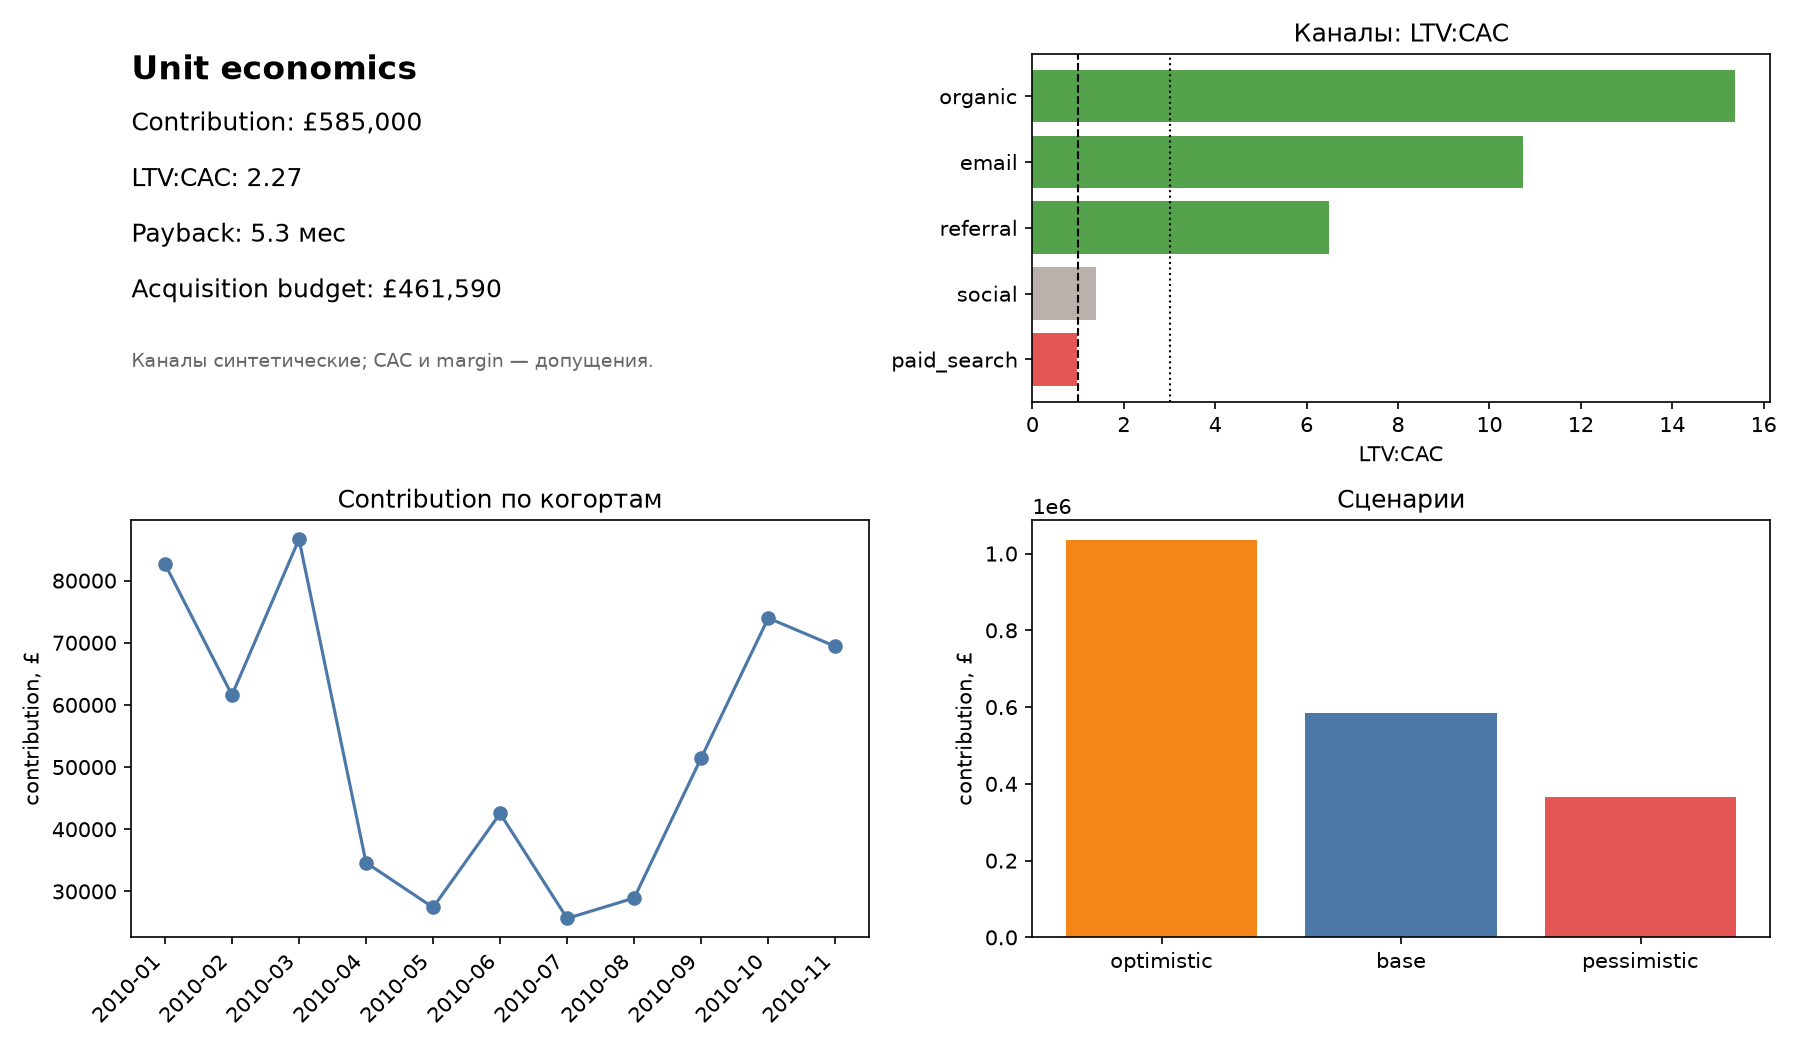

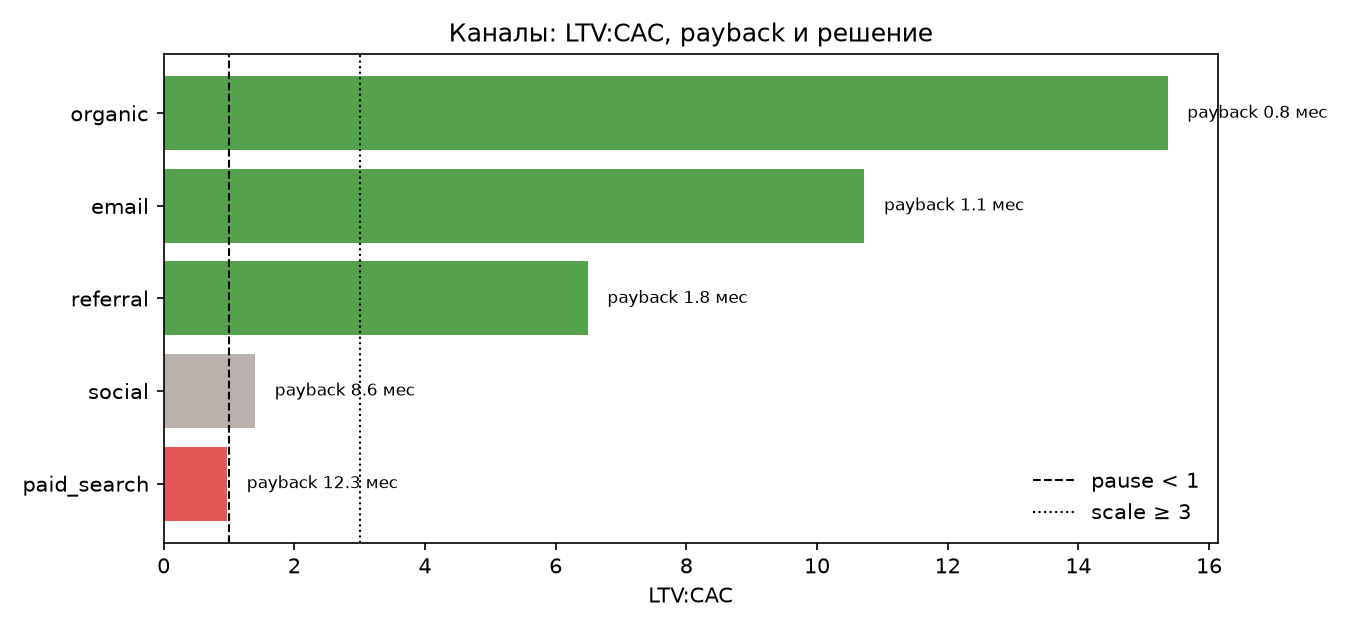

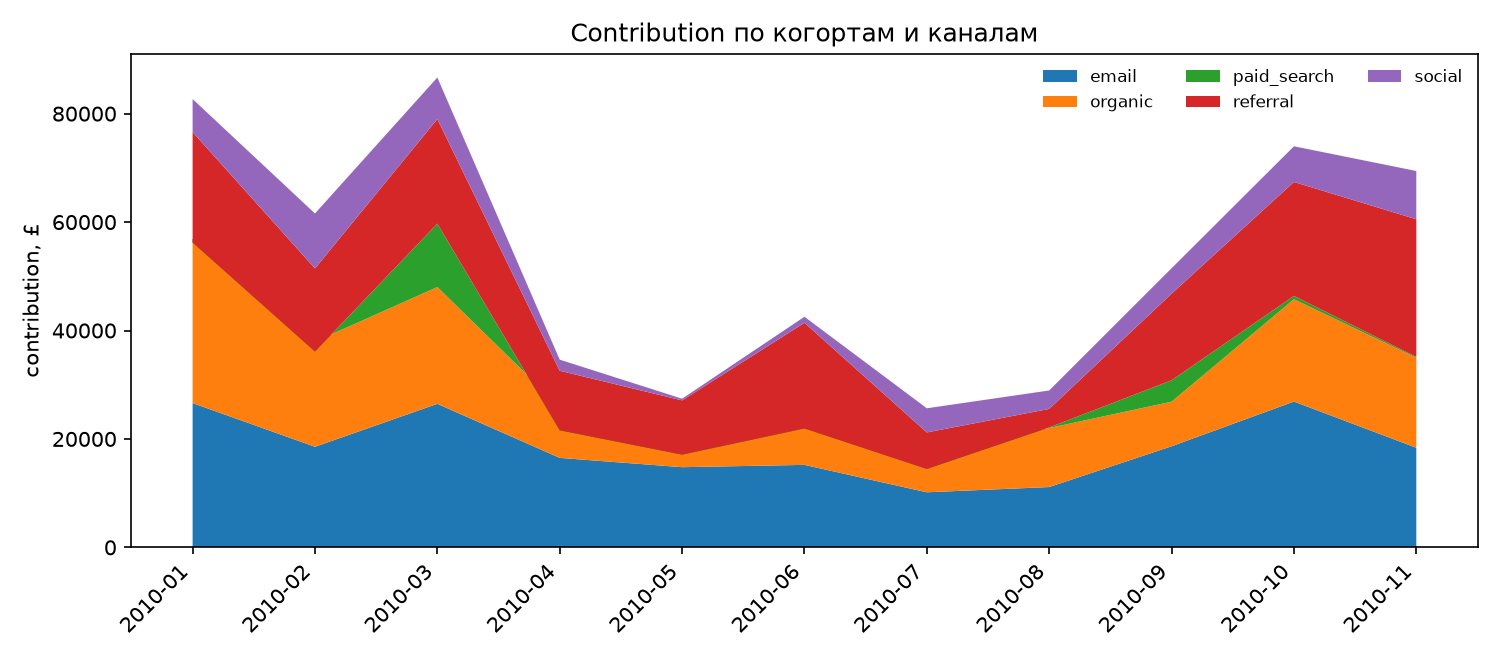

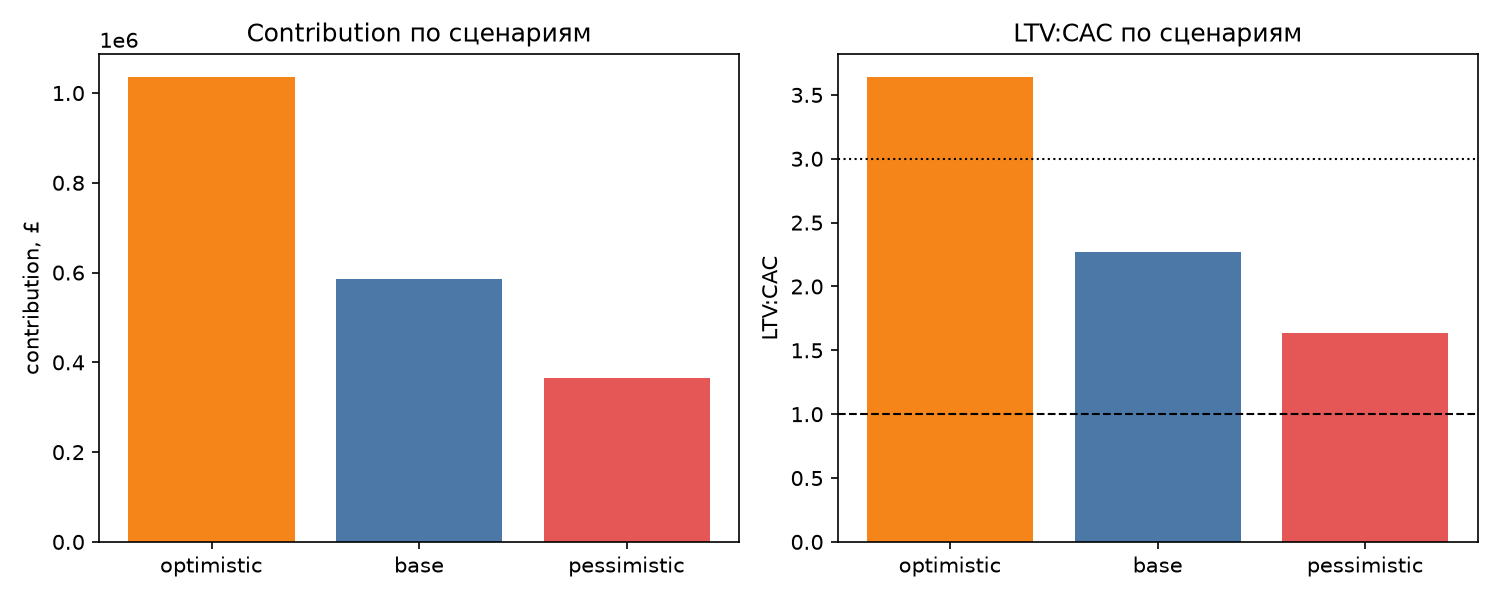

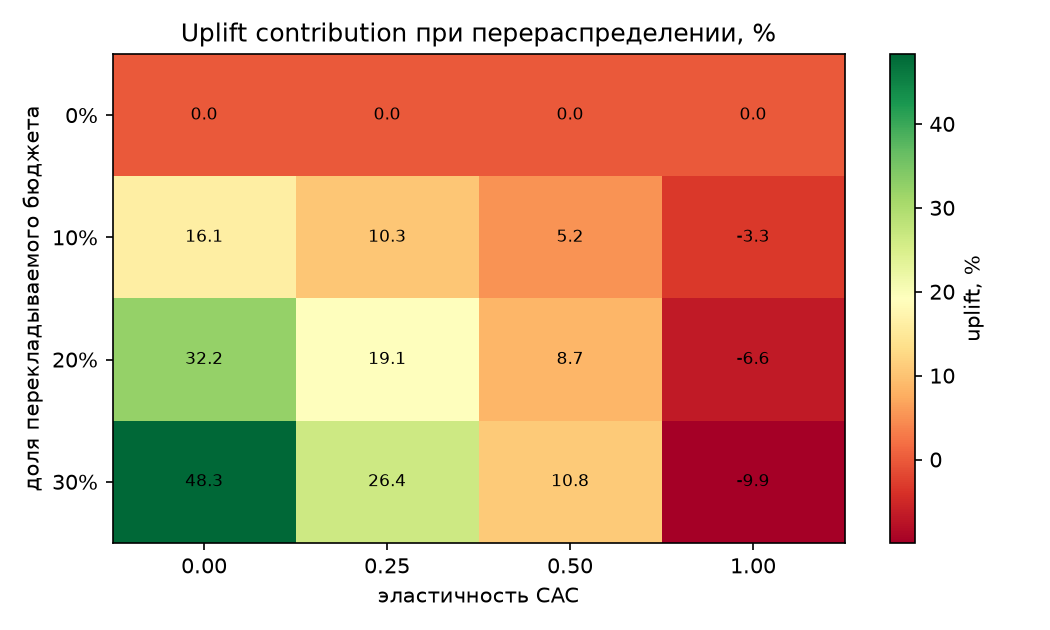

In [5]:
for name in ['01-dashboard-overview', '02-channel-unit-economics', '03-cohort-contribution',
             '04-scenarios', '05-reallocation']:
    display(Image(filename=str(CASE_DASHBOARD / 'reports' / 'figures' / f'{name}.png')))


## Вывод

- Base: contribution £585 тыс., LTV:CAC 2.27, payback 5.3 мес.
- `paid_search`: LTV:CAC 0.97, payback 12.3 мес → pause.
- `social`: 1.40 / 8.6 мес → keep.
- `email`, `referral`, `organic`: 15.4 / 10.7 / 6.5 → scale.
- 20 % shift при эластичности 0.5 даёт +£50.8 тыс. (+8.7 %); при эластичности
  ≥0.8 перекладывание перестаёт окупаться.
